# Thai Next-Word Prediction — KaggleHub + HSE Thai Corpus

`kagglehub` → HSE Thai Corpus (CSV) → Thai tokenization → streaming `tf.data` → causal Transformer Encoder → next-word prediction → **F1 evaluation** → 5-word generation → TFLite.

This notebook does **not** use `files.upload()`; the dataset is downloaded directly with `kagglehub`.

In [16]:
# ============================================================
# 1. INSTALL DEPENDENCIES
# ============================================================

import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "pythainlp",
    "kagglehub",
    "scikit-learn"
])

print("Dependencies installed successfully.")

Dependencies installed successfully.


In [17]:
# ============================================================
# 2. IMPORTS + CONFIG
# ============================================================

import os
import re
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import tensorflow as tf

import kagglehub

from pythainlp.tokenize import word_tokenize

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------

VOCAB_SIZE = 20_000
MAX_LEN = 30

EMBED_DIM = 128
NUM_HEADS = 4
FF_DIM = 256
DROPOUT = 0.25          # was 0.10 (more regularization)

BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# ------------------------------------------------------------
# Data configuration
# ------------------------------------------------------------

# Rows read from EACH csv file (None = read everything).
# Tokenizing the whole 448 MB corpus is very slow, so start small.
MAX_ROWS_PER_FILE = 200_000

# Rows used to count word frequencies for the vocabulary
VOCAB_SCAN_ROWS = 100_000

# Initial experiment size.
# Increase after confirming that the pipeline works.
MAX_TRAIN_SAMPLES = 100000
MAX_VAL_SAMPLES = 50000

VAL_FRACTION = 0.05

# Works on Kaggle, Colab and local machines
if os.path.isdir("/kaggle/working"):
    OUTPUT_DIR = "/kaggle/working"
elif os.path.isdir("/content"):
    OUTPUT_DIR = "/content"
else:
    OUTPUT_DIR = os.getcwd()

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Output dir:", OUTPUT_DIR)

TensorFlow: 2.22.0-rc0
GPU: []
Output dir: /Users/pan/CS/AI_project


In [18]:
# ============================================================
# 3. DOWNLOAD DATASET
# ============================================================

dataset_path = kagglehub.dataset_download("rtatman/hse-thai-corpus")

print("Dataset path:", dataset_path)

csv_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in sorted(files):
        full_path = os.path.join(root, file)
        print(full_path)

        if file.lower().endswith(".csv"):
            csv_files.append(full_path)

if not csv_files:
    raise FileNotFoundError("No CSV file found in the dataset folder.")

Dataset path: /Users/pan/.cache/kagglehub/datasets/rtatman/hse-thai-corpus/versions/1
/Users/pan/.cache/kagglehub/datasets/rtatman/hse-thai-corpus/versions/1/thai-government-corpus.csv
/Users/pan/.cache/kagglehub/datasets/rtatman/hse-thai-corpus/versions/1/thai-wikipedia-corpus.csv


In [19]:
# ============================================================
# 4. LOAD CSV + INSPECT SCHEMA
# ============================================================
# (replaces the old `hf_dataset`, which was never defined -> NameError)

frames = []

for path in csv_files:
    part = pd.read_csv(
        path,
        nrows=MAX_ROWS_PER_FILE,
        on_bad_lines="skip"
    )
    part["source_file"] = os.path.basename(path)
    frames.append(part)

    print(f"{os.path.basename(path)}: {len(part):,} rows")

df = pd.concat(frames, ignore_index=True)

# Shuffle so train / validation contain both corpora
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

print("\nColumns:")
print(df.dtypes)

print("\nNumber of rows:", f"{len(df):,}")

print("\nFirst example:")
print(df.iloc[0].to_dict())

thai-government-corpus.csv: 265 rows
thai-wikipedia-corpus.csv: 98,156 rows

Columns:
article        object
text              str
source_file       str
dtype: object

Number of rows: 98,421

First example:
{'article': 'ยูโรเปี้ยน ซูเปอร์ลีก', 'text': 'ยูโร เปี้ยน    ซูเปอร์ ลีก  ยูโร เปี้ยน    ซูเปอร์ ลีก    รายการ ฟุตบอล ชิง แชมป์  สโมสร ยุโรป ซึ่ง เกิด ขึ้น จาก แนว ความคิด ของ ฟลอเรน  ติ โน เปเรซ    ประธาน สโมสร รี ล    มาดริด    เมื่อ วัน ที่ 4 กรกฎาคม 2552 ที่ ต้องการ ให้ บรรดา สโมสร ชั้น นำ ของ ยุโรป แยก ตัว ออก มา จาก ยู ฟ่าแชมเปียนส์  ลีก    แล้ว จัดตั้ง รายการ ฟุตบอล ยูโร เปี้ยน    ซูเปอร์ ลีก    ขึ้น มา แต่ ไม่ ได้ รับ การ ตอบ สนอง จน กระทั่ง วัน ที่ 2 มีนาคม 2559 หนังสือพิมพ์ เดอะ ซัน    ได้ รายงาน ว่า  บรรดา ผู้  บริหาร ของ สโมสร ชั้น นำ ใน ศิึก    พรีเมียร์  ลีก    ทั้งหมด 5 คน ได้แก่ เอ็ด วูด  เวิร์ด รอง ประธาน บริหาร แมนเชสเตอร์  ยู ไน เต็ด    , บรูซ บัค    ประธาน สโมสร เชลซี , อิ วาน กา ซิ ดิส    ประธาน บริหาร อาร์เซนอล    , เฟร์  ราน โซ เรีย  โน ประธาน บริหาร แมนเชสเตอร

## 5. Automatically find the text column

The notebook loads the CSV files with pandas and picks the string column with the longest average text.

If the inspection cell shows a specific column you prefer, set `TEXT_COLUMN` manually.

In [20]:
# ============================================================
# 5. FIND TEXT COLUMN
# ============================================================

TEXT_COLUMN = None   # set manually if the auto-detection picks the wrong one

def detect_text_column(frame, manual_column=None):

    if manual_column is not None:
        if manual_column not in frame.columns:
            raise ValueError(
                f"Column '{manual_column}' not found. "
                f"Available columns: {list(frame.columns)}"
            )
        return manual_column

    best_name = None
    best_len = -1.0

    for name in frame.columns:

        if name == "source_file":
            continue

        # works for both pandas 2.x (object) and pandas 3.x (str)
        if pd.api.types.is_numeric_dtype(frame[name]):
            continue

        mean_len = (
            frame[name]
            .dropna()
            .astype(str)
            .head(1000)
            .str.len()
            .mean()
        )

        if mean_len > best_len:
            best_name = name
            best_len = mean_len

    if best_name is None:
        raise ValueError(
            "Could not automatically find a text column. "
            f"Available columns: {list(frame.columns)}"
        )

    return best_name


TEXT_COLUMN = detect_text_column(df, TEXT_COLUMN)

print("Using text column:", TEXT_COLUMN)

# Remove duplicate texts BEFORE the train/validation split.
# Otherwise the same sentence can be in both sets and the model just memorizes it.
before = len(df)
df = df.dropna(subset=[TEXT_COLUMN])
df = df.drop_duplicates(subset=[TEXT_COLUMN]).reset_index(drop=True)
print(f"Removed {before - len(df):,} duplicate/empty rows ({(before - len(df)) / max(before, 1):.1%})")

texts = [
    t for t in df[TEXT_COLUMN].dropna().astype(str).tolist()
    if t.strip()
]

row_count = len(texts)

VAL_START_ROW = int(row_count * (1.0 - VAL_FRACTION))

print("Usable rows:", f"{row_count:,}")

Using text column: text
Removed 548 duplicate/empty rows (0.6%)
Usable rows: 97,873


In [21]:
# ============================================================
# 6. TEST TEXT + THAI TOKENIZATION
# ============================================================

def clean_text(text):
    text = str(text)
    text = text.replace("\\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def thai_tokenize(text):
    text = clean_text(text)

    if not text:
        return []

    tokens = word_tokenize(
        text,
        engine="newmm",
        keep_whitespace=False
    )

    return [
        token.strip()
        for token in tokens
        if token.strip()
    ]


example = texts[0]

print("Example:")
print(example)

print("\nTokens:")
print(thai_tokenize(example)[:50])

Example:
ยูโร เปี้ยน    ซูเปอร์ ลีก  ยูโร เปี้ยน    ซูเปอร์ ลีก    รายการ ฟุตบอล ชิง แชมป์  สโมสร ยุโรป ซึ่ง เกิด ขึ้น จาก แนว ความคิด ของ ฟลอเรน  ติ โน เปเรซ    ประธาน สโมสร รี ล    มาดริด    เมื่อ วัน ที่ 4 กรกฎาคม 2552 ที่ ต้องการ ให้ บรรดา สโมสร ชั้น นำ ของ ยุโรป แยก ตัว ออก มา จาก ยู ฟ่าแชมเปียนส์  ลีก    แล้ว จัดตั้ง รายการ ฟุตบอล ยูโร เปี้ยน    ซูเปอร์ ลีก    ขึ้น มา แต่ ไม่ ได้ รับ การ ตอบ สนอง จน กระทั่ง วัน ที่ 2 มีนาคม 2559 หนังสือพิมพ์ เดอะ ซัน    ได้ รายงาน ว่า  บรรดา ผู้  บริหาร ของ สโมสร ชั้น นำ ใน ศิึก    พรีเมียร์  ลีก    ทั้งหมด 5 คน ได้แก่ เอ็ด วูด  เวิร์ด รอง ประธาน บริหาร แมนเชสเตอร์  ยู ไน เต็ด    , บรูซ บัค    ประธาน สโมสร เชลซี , อิ วาน กา ซิ ดิส    ประธาน บริหาร อาร์เซนอล    , เฟร์  ราน โซ เรีย  โน ประธาน บริหาร แมนเชสเตอร์  ซิตี้ และ เอียน อายร์    ประธาน บริหาร ลิเวอร์พูล    ร่วม ด้วย สตี  เฟ่น    รอสส์    นัก ธุรกิจ ชาว  อเมริกัน และ เจ้าของ ทีม ไม  อา มี ดอลฟินส์    ได้ นัด ประชุม กัน อย่าง ลับ ๆ ที่ โรงแรม เดอะ ดอร์เชสเตอร์    ใน ย่าน พาร์  ค เลน ของ กรุง 

## 7. Build vocabulary

The HSE corpus is scanned through the Hugging Face Dataset and token frequencies are counted.

Vocabulary:

- `<PAD>` = 0
- `<UNK>` = 1
- `<START>` = 2
- remaining IDs = most frequent Thai tokens

The final vocabulary is limited to 20,000 tokens.

In [22]:
# ============================================================
# 7. BUILD VOCABULARY  (training rows only -> no validation leakage)
# ============================================================

counter = Counter()

scan_rows = min(VOCAB_SCAN_ROWS, VAL_START_ROW)

for i in range(scan_rows):

    counter.update(
        thai_tokenize(texts[i])
    )

    if (i + 1) % 10_000 == 0:
        print(
            f"Processed: {i + 1:,} / {scan_rows:,} "
            f"| unique tokens: {len(counter):,}"
        )

print("\nVocabulary scan complete.")
print("Unique tokens:", f"{len(counter):,}")

word_to_id = {
    "<PAD>": 0,
    "<UNK>": 1,
    "<START>": 2
}

for idx, (word, _) in enumerate(
    counter.most_common(VOCAB_SIZE - 3),
    start=3
):
    word_to_id[word] = idx

id_to_word = {
    idx: word
    for word, idx in word_to_id.items()
}

print("Final vocabulary:", len(word_to_id))

Processed: 10,000 / 92,979 | unique tokens: 67,020
Processed: 20,000 / 92,979 | unique tokens: 102,826
Processed: 30,000 / 92,979 | unique tokens: 133,539
Processed: 40,000 / 92,979 | unique tokens: 161,788
Processed: 50,000 / 92,979 | unique tokens: 186,307
Processed: 60,000 / 92,979 | unique tokens: 210,312
Processed: 70,000 / 92,979 | unique tokens: 232,622
Processed: 80,000 / 92,979 | unique tokens: 254,301
Processed: 90,000 / 92,979 | unique tokens: 273,547

Vocabulary scan complete.
Unique tokens: 279,431
Final vocabulary: 20000


In [23]:
# ============================================================
# 8. ENCODE / EXAMPLE
# ============================================================

def encode_tokens(tokens):
    return [
        word_to_id.get(token, 1)
        for token in tokens
    ]


example_tokens = thai_tokenize(example)
example_ids = encode_tokens(example_tokens)

print("Tokens:")
print(example_tokens[:30])

print("\nIDs:")
print(example_ids[:30])

Tokens:
['ยูโร', 'เปี้ยน', 'ซูเปอร์', 'ลีก', 'ยูโร', 'เปี้ยน', 'ซูเปอร์', 'ลีก', 'รายการ', 'ฟุตบอล', 'ชิง', 'แชมป์', 'สโมสร', 'ยุโรป', 'ซึ่ง', 'เกิด', 'ขึ้น', 'จาก', 'แนว', 'ความคิด', 'ของ', 'ฟลอ', 'เร', 'น', 'ติ', 'โน', 'เป', 'เร', 'ซ', 'ประธาน']

IDs:
[2262, 7593, 1426, 658, 2262, 7593, 1426, 658, 283, 317, 421, 386, 484, 558, 28, 70, 37, 12, 375, 955, 9, 9399, 315, 97, 444, 408, 2049, 315, 751, 663]


## 9. Create next-word examples on demand

We do not construct giant `X_train` and `y_train` arrays.

For each sentence:

```text
วันนี้ | ฉัน | ไป | มหาวิทยาลัย
```

the generator produces:

```text
วันนี้                         → ฉัน
วันนี้ ฉัน                    → ไป
วันนี้ ฉัน ไป                 → มหาวิทยาลัย
```

with left padding up to `MAX_LEN`.

In [24]:
# ============================================================
# 9. STREAMING EXAMPLE GENERATOR
# ============================================================

def row_to_examples(text):

    tokens = thai_tokenize(text)

    if len(tokens) < 2:
        return

    ids = encode_tokens(tokens)

    for i in range(1, len(ids)):

        start = max(0, i - MAX_LEN)

        context = ids[start:i]
        target = ids[i]

        if len(context) < MAX_LEN:
            context = (
                [0] * (MAX_LEN - len(context))
                + context
            )

        yield (
            np.asarray(context, dtype=np.int32),
            np.int32(target)
        )


def dataset_generator(
    text_list,
    start_row,
    end_row,
    max_samples=None
):

    count = 0

    for row_index in range(
        start_row,
        min(end_row, len(text_list))
    ):

        for x, y in row_to_examples(text_list[row_index]):

            yield x, y

            count += 1

            if (
                max_samples is not None
                and count >= max_samples
            ):
                return

In [25]:
# ============================================================
# 10. TRAIN / VALIDATION SPLIT
# ============================================================

print("Total rows:", f"{row_count:,}")
print("Train rows:", f"{VAL_START_ROW:,}")
print("Validation rows:", f"{row_count - VAL_START_ROW:,}")

Total rows: 97,873
Train rows: 92,979
Validation rows: 4,894


In [26]:
# ============================================================
# 11. TF.DATA
# ============================================================

output_signature = (
    tf.TensorSpec(shape=(MAX_LEN,), dtype=tf.int32),
    tf.TensorSpec(shape=(), dtype=tf.int32)
)

train_ds = tf.data.Dataset.from_generator(
    lambda: dataset_generator(
        texts, 0, VAL_START_ROW, MAX_TRAIN_SAMPLES
    ),
    output_signature=output_signature
)

val_ds = tf.data.Dataset.from_generator(
    lambda: dataset_generator(
        texts, VAL_START_ROW, row_count, MAX_VAL_SAMPLES
    ),
    output_signature=output_signature
)

# .cache() -> Thai tokenization runs only once, not on every epoch
train_ds = (
    train_ds
    .cache()
    .shuffle(100_000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("tf.data created.")

# Check that data is actually produced
for x_batch, y_batch in train_ds.take(1):

    print("X shape:", x_batch.shape)
    print("y shape:", y_batch.shape)

    print("First X:")
    print(x_batch[0].numpy())

    print("First target:")
    print(y_batch[0].numpy())

    break

tf.data created.
X shape: (128, 30)
y shape: (128,)
First X:
[  81    9 1444  160   15    3   10  473 2757  144    7  576 9596   11
   43    8  422  473   78   59    5   19  694 9596   19   34   36    3
  192  579]
First target:
27


# 12. Transformer Encoder with Causal Attention

The model uses causal self-attention so the representation at a position cannot use future tokens.

Architecture:

**Token IDs → Embedding + Position → Causal Transformer Encoder → Last position → Dense(20,000) → Softmax**

In [27]:
# ============================================================
# 12. EMBEDDING + TRANSFORMER BLOCK
# ============================================================

@tf.keras.utils.register_keras_serializable(package="thai")
class TokenAndPositionEmbedding(tf.keras.layers.Layer):

    def __init__(self, vocab_size, max_len, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.max_len = max_len
        self.embed_dim = embed_dim

        self.token_emb = tf.keras.layers.Embedding(
            vocab_size, embed_dim, name="token_embedding"
        )
        self.pos_emb = tf.keras.layers.Embedding(
            max_len, embed_dim, name="position_embedding"
        )

    def call(self, x):
        positions = tf.range(start=0, limit=tf.shape(x)[-1])
        return self.token_emb(x) + self.pos_emb(positions)

    def get_config(self):
        config = super().get_config()
        config.update({
            "vocab_size": self.vocab_size,
            "max_len": self.max_len,
            "embed_dim": self.embed_dim,
        })
        return config


@tf.keras.utils.register_keras_serializable(package="thai")
class LastTimestep(tf.keras.layers.Layer):
    """Takes the representation of the last position: (B, T, D) -> (B, D)."""

    def call(self, x):
        return x[:, -1, :]


@tf.keras.utils.register_keras_serializable(package="thai")
class TransformerBlock(tf.keras.layers.Layer):

    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_dim,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout

        self.att = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )

        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation="gelu"),
            tf.keras.layers.Dense(embed_dim)
        ])

        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = tf.keras.layers.Dropout(dropout)
        self.dropout2 = tf.keras.layers.Dropout(dropout)

    def call(self, x, training=False):

        attention_output = self.att(
            x,
            x,
            use_causal_mask=True,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.norm2(x + ffn_output)

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout": self.dropout_rate,
        })
        return config

In [28]:
# ============================================================
# 13. BUILD MODEL
# ============================================================

token_input = tf.keras.Input(
    shape=(MAX_LEN,),
    dtype=tf.int32,
    name="tokens"
)

x = TokenAndPositionEmbedding(
    vocab_size=len(word_to_id),
    max_len=MAX_LEN,
    embed_dim=EMBED_DIM,
    name="embedding"
)(token_input)

x = TransformerBlock(
    embed_dim=EMBED_DIM,
    num_heads=NUM_HEADS,
    ff_dim=FF_DIM,
    dropout=DROPOUT
)(x)

x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)

# Last position predicts the next token
x = LastTimestep(name="last_timestep")(x)

x = tf.keras.layers.Dropout(DROPOUT)(x)

output = tf.keras.layers.Dense(
    len(word_to_id),
    activation="softmax",
    name="next_word"
)(x)

model = tf.keras.Model(token_input, output)

model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5, name="top5_accuracy"
        )
    ]
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tokens (InputLayer)             │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding                       │ (None, 30, 128)        │     2,563,840 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 30, 128)        │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_5           │ (None, 30, 128)        │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_timestep (LastTimestep)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_word (Dense)               │ (None, 20000)          │     2,580,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,276,576 (20.13 MB)

 Trainable params: 5,276,576 (20.13 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# ============================================================
# 14. TRAIN
# ============================================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        min_delta=0.001,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30


/Users/pan/CS/AI_project/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


782/782 ━━━━━━━━━━━━━━━━━━━━ 50s 63ms/step - accuracy: 0.1095 - loss: 6.5169 - top5_accuracy: 0.2186 - val_accuracy: 0.1070 - val_loss: 6.6668 - val_top5_accuracy: 0.2320 - learning_rate: 0.0010
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 52s 66ms/step - accuracy: 0.1892 - loss: 5.1800 - top5_accuracy: 0.3555 - val_accuracy: 0.1124 - val_loss: 6.6377 - val_top5_accuracy: 0.2430 - learning_rate: 0.0010
Epoch 3/30
781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.2248 - loss: 4.5227 - top5_accuracy: 0.4177
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
782/782 ━━━━━━━━━━━━━━━━━━━━ 52s 66ms/step - accuracy: 0.2247 - loss: 4.5227 - top5_accuracy: 0.4177 - val_accuracy: 0.1176 - val_loss: 6.8373 - val_top5_accuracy: 0.2487 - learning_rate: 0.0010
Epoch 4/30
781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.2680 - loss: 3.9157 - top5_accuracy: 0.4887
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
782/782 ━━━━━━━━━━━━━━━━━━━━ 6

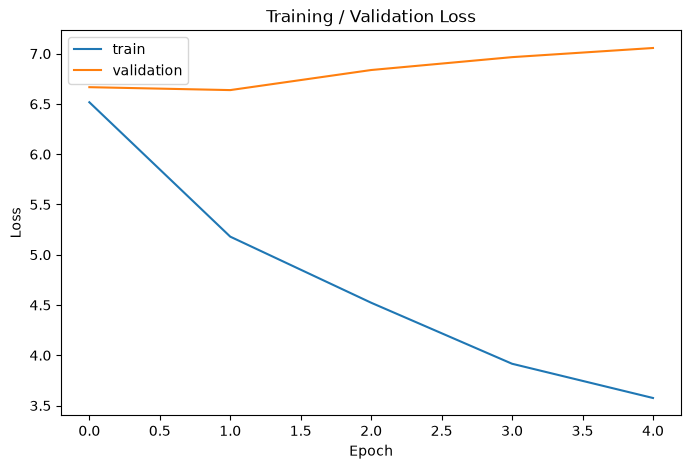

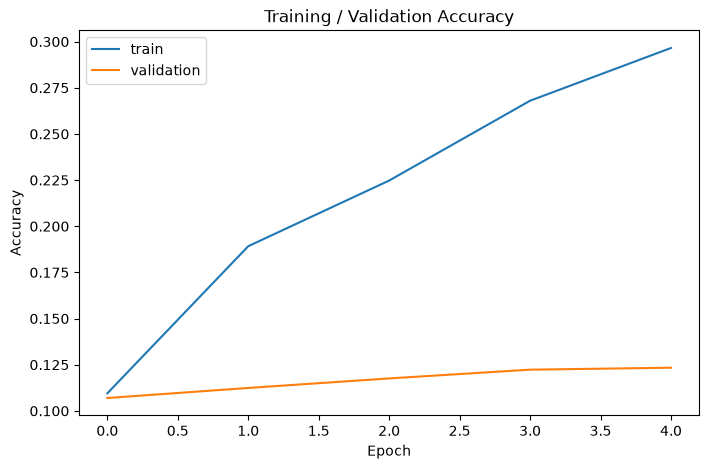

In [30]:
# ============================================================
# 15. TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    history.history["loss"],
    label="train"
)
plt.plot(
    history.history["val_loss"],
    label="validation"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history.history["accuracy"],
    label="train"
)
plt.plot(
    history.history["val_accuracy"],
    label="validation"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training / Validation Accuracy")
plt.legend()
plt.show()

## 15.5 F1 Score (validation set)

Next-word prediction is a multi-class problem with ~20,000 classes, so three F1 averages are reported:

- **Micro F1** – counts every prediction equally (for single-label multi-class this equals accuracy)
- **Macro F1** – averages F1 over every word class equally (rare words count as much as common ones → naturally low)
- **Weighted F1** – averages F1 over classes, weighted by how often each word appears

In [31]:
# ============================================================
# 15.5 F1 SCORE
# ============================================================

from sklearn.metrics import f1_score, precision_score, recall_score


def collect_predictions(dataset, max_batches=None):
    """Runs the model batch by batch (never stores the 20k-wide probability matrix)."""

    y_true_all = []
    y_pred_all = []
    top5_hits = 0
    total = 0

    for batch_index, (x_batch, y_batch) in enumerate(dataset):

        if max_batches is not None and batch_index >= max_batches:
            break

        probs = model(x_batch, training=False)

        pred = tf.argmax(probs, axis=-1, output_type=tf.int32)
        top5 = tf.math.top_k(probs, k=5).indices

        y_np = y_batch.numpy()

        top5_hits += int(
            np.any(top5.numpy() == y_np[:, None], axis=1).sum()
        )
        total += len(y_np)

        y_true_all.append(y_np)
        y_pred_all.append(pred.numpy())

    return (
        np.concatenate(y_true_all),
        np.concatenate(y_pred_all),
        top5_hits / max(total, 1)
    )


y_true, y_pred, top5_acc = collect_predictions(val_ds)

print("Validation samples:", f"{len(y_true):,}")

results = {
    "accuracy (top-1)": float((y_true == y_pred).mean()),
    "top-5 accuracy":   top5_acc,

    "micro F1":    f1_score(y_true, y_pred, average="micro",    zero_division=0),
    "macro F1":    f1_score(y_true, y_pred, average="macro",    zero_division=0),
    "weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),

    "weighted precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
    "weighted recall":    recall_score(y_true, y_pred, average="weighted",    zero_division=0),
}

print()
for name, value in results.items():
    print(f"{name:20s}: {value:.4f}")

# ------------------------------------------------------------
# Sanity check: how much of the score comes from <UNK>?
# ------------------------------------------------------------

unk_ratio = float((y_true == 1).mean())
print(f"\nShare of <UNK> targets in validation: {unk_ratio:.2%}")

mask = (y_true != 0) & (y_true != 1)   # drop <PAD> and <UNK> targets

print(f"Validation samples without <UNK>/<PAD>: {mask.sum():,}")
print(f"accuracy (no UNK):    {float((y_true[mask] == y_pred[mask]).mean()):.4f}")
print(f"micro F1 (no UNK):    {f1_score(y_true[mask], y_pred[mask], average='micro',    zero_division=0):.4f}")
print(f"macro F1 (no UNK):    {f1_score(y_true[mask], y_pred[mask], average='macro',    zero_division=0):.4f}")
print(f"weighted F1 (no UNK): {f1_score(y_true[mask], y_pred[mask], average='weighted', zero_division=0):.4f}")

# ------------------------------------------------------------
# F1 of the most frequent target words
# ------------------------------------------------------------

top_classes = [
    int(c) for c, _ in Counter(y_true.tolist()).most_common(15)
]

per_class_f1 = f1_score(
    y_true,
    y_pred,
    labels=top_classes,
    average=None,
    zero_division=0
)

print("\nF1 of the 15 most frequent target words:")
print(f"{'word':<14}{'count':>8}{'F1':>8}")

true_counts = Counter(y_true.tolist())

for class_id, f1_value in zip(top_classes, per_class_f1):
    print(
        f"{id_to_word.get(class_id, '?'):<14}"
        f"{true_counts[class_id]:>8}"
        f"{f1_value:>8.3f}"
    )

Validation samples: 50,000

accuracy (top-1)    : 0.1124
top-5 accuracy      : 0.2430
micro F1            : 0.1124
macro F1            : 0.0145
weighted F1         : 0.0843
weighted precision  : 0.0854
weighted recall     : 0.1124

Share of <UNK> targets in validation: 2.79%
Validation samples without <UNK>/<PAD>: 48,607
accuracy (no UNK):    0.1074
micro F1 (no UNK):    0.1074
macro F1 (no UNK):    0.0146
weighted F1 (no UNK): 0.0825

F1 of the 15 most frequent target words:
word             count      F1
<UNK>             1393   0.175
ที่               1190   0.160
ใน                 932   0.117
เป็น               918   0.107
และ                776   0.055
ของ                749   0.120
.                  748   0.583
การ                668   0.141
มี                 616   0.108
ได้                575   0.088
พระ                475   0.181
ว่า                393   0.297
ไป                 359   0.159
'                  358   0.145
กับ                354   0.319


In [32]:
# ============================================================
# 16. TOP-K NEXT WORD
# ============================================================

def encode_text(text):

    tokens = thai_tokenize(text)

    return [
        word_to_id.get(
            token,
            1
        )
        for token in tokens
    ]


def predict_next_words(
    text,
    top_k=5
):

    ids = encode_text(text)

    if not ids:
        return []

    context = ids[-MAX_LEN:]

    if len(context) < MAX_LEN:
        context = (
            [0] * (MAX_LEN - len(context))
            + context
        )

    x = np.asarray(
        [context],
        dtype=np.int32
    )

    probabilities = model.predict(
        x,
        verbose=0
    )[0]

    top_ids = np.argsort(
        probabilities
    )[-top_k:][::-1]

    return [
        (
            id_to_word.get(
                int(token_id),
                "<UNK>"
            ),
            float(
                probabilities[token_id]
            )
        )
        for token_id in top_ids
    ]


def print_suggestions(
    text,
    top_k=5
):

    print("\nInput:")
    print(text)

    print("\nPredictions:")

    for i, (word, probability) in enumerate(
        predict_next_words(
            text,
            top_k
        ),
        start=1
    ):

        print(
            f"{i}. {word} "
            f"{probability * 100:.2f}%"
        )

In [33]:
# ============================================================
# 17. GENERATE 5 WORDS
# ============================================================

def generate_words(
    text,
    num_words=5
):

    result = text
    generated = []

    for _ in range(num_words):

        predictions = predict_next_words(
            result,
            top_k=1
        )

        if not predictions:
            break

        next_word = predictions[0][0]

        if next_word in {
            "<PAD>",
            "<UNK>",
            "<START>"
        }:
            break

        generated.append(
            next_word
        )

        result = (
            result.rstrip()
            + " "
            + next_word
        )

    return result, generated


text = "วันนี้ฉันกำลังจะไป"

print_suggestions(
    text,
    top_k=5
)

result, generated = generate_words(
    text,
    num_words=5
)

print("\nGenerated 5 words:")
print(generated)

print("\nResult:")
print(result)


Input:
วันนี้ฉันกำลังจะไป

Predictions:
1. เป็น 6.73%
2. ใน 5.47%
3. ยัง 4.24%
4. ) 4.04%
5. ถึง 3.28%

Generated 5 words:
['เป็น', 'นัก', 'แสดง', 'ชาว', 'ไทย']

Result:
วันนี้ฉันกำลังจะไป เป็น นัก แสดง ชาว ไทย


In [34]:
# ============================================================
# 18. INTERACTIVE TEST
# ============================================================

print("Thai Next-Word Prediction")
print("พิมพ์ exit เพื่อออก\n")

while True:

    text = input(
        "Enter Thai sentence: "
    )

    if text.lower().strip() == "exit":
        break

    if not text.strip():
        continue

    print_suggestions(
        text,
        top_k=5
    )

    result, generated = generate_words(
        text,
        num_words=5
    )

    print("\nGenerate 5 words:")
    print(result)
    print()

Thai Next-Word Prediction
พิมพ์ exit เพื่อออก


Input:
วันนี้ฉันจะ

Predictions:
1. เป็น 13.33%
2. มี 7.24%
3. มิ 4.10%
4. ทรง 2.02%
5. ใช้ 1.75%

Generate 5 words:
วันนี้ฉันจะ เป็น นัก แสดง ชาว ไทย


Input:
สวัสดีคุณสบาย

Predictions:
1. ( 3.11%
2. ไป 2.48%
3. มา 2.45%
4. สูง 2.15%
5. หรือ 1.66%

Generate 5 words:
สวัสดีคุณสบาย ( เศวตฉัตร ( เศวตฉัตร )


Input:
วันนี้ฉันมีความ

Predictions:
1. สามารถ 4.73%
2. รัก 3.98%
3. สำเร็จ 3.71%
4. ผิด 3.42%
5. เป็น 3.25%

Generate 5 words:
วันนี้ฉันมีความ สามารถ เป็น นัก แสดง ชาว



In [35]:
# ============================================================
# 19. SAVE KERAS + VOCABULARY
# ============================================================

MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "thai_next_word_transformer.keras"
)

VOCAB_PATH = os.path.join(
    OUTPUT_DIR,
    "thai_vocab.json"
)

model.save(MODEL_PATH)

with open(VOCAB_PATH, "w", encoding="utf-8") as f:
    json.dump(
        word_to_id,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Saved:")
print(MODEL_PATH)
print(VOCAB_PATH)

Saved:
/Users/pan/CS/AI_project/thai_next_word_transformer.keras
/Users/pan/CS/AI_project/thai_vocab.json


In [36]:
# ============================================================
# 20. EXPORT TFLITE
# ============================================================

TFLITE_PATH = os.path.join(
    OUTPUT_DIR,
    "thai_next_word_transformer.tflite"
)

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

size_mb = os.path.getsize(TFLITE_PATH) / (1024 ** 2)

print("TFLite:")
print(TFLITE_PATH)
print(f"Size: {size_mb:.2f} MB")

INFO:tensorflow:Assets written to: /var/folders/vj/_7d8_p4x59jcqfwz9dc8k8vm0000gn/T/tmpeszt1p66/assets


INFO:tensorflow:Assets written to: /var/folders/vj/_7d8_p4x59jcqfwz9dc8k8vm0000gn/T/tmpeszt1p66/assets


Saved artifact at '/var/folders/vj/_7d8_p4x59jcqfwz9dc8k8vm0000gn/T/tmpeszt1p66'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30), dtype=tf.int32, name='tokens')
Output Type:
  TensorSpec(shape=(None, 20000), dtype=tf.float32, name=None)
Captures:
  5272091968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272092176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272228608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272229648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272228816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272230064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272229024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272230480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272229440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272231104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5272229232: TensorSpec(shape=(), 

W0000 00:00:1791363122.878173  382473 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1791363122.878312  382473 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1791363122.880484  382473 reader.cc:83] Reading SavedModel from: /var/folders/vj/_7d8_p4x59jcqfwz9dc8k8vm0000gn/T/tmpeszt1p66
I0000 00:00:1791363122.880991  382473 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791363122.880995  382473 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/vj/_7d8_p4x59jcqfwz9dc8k8vm0000gn/T/tmpeszt1p66
I0000 00:00:1791363122.886729  382473 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1791363122.887555  382473 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1791363122.919189  382473 loader.cc:221] Running initialization op on SavedModel bundle at path: /var/folders/vj/_7d8_p4x59jcqfwz9dc8k8vm0000gn/T/tmpeszt1p66
I0000 00:00:1791363122.928485  382473 lo

In [37]:
# ============================================================
# 21. TEST TFLITE
# ============================================================

interpreter = tf.lite.Interpreter(
    model_path=TFLITE_PATH
)

interpreter.allocate_tensors()

input_details = (
    interpreter
    .get_input_details()
)

output_details = (
    interpreter
    .get_output_details()
)

print("Input:")
print(input_details)

print("\nOutput:")
print(output_details)

for x_batch, y_batch in train_ds.take(1):

    sample = x_batch[:1].numpy()

    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    tflite_output = (
        interpreter
        .get_tensor(
            output_details[0]["index"]
        )
    )

    print(
        "\nTFLite output shape:",
        tflite_output.shape
    )

    print(
        "Predicted ID:",
        int(
            np.argmax(
                tflite_output[0]
            )
        )
    )

    break

/Users/pan/CS/AI_project/.venv/lib/python3.14/site-packages/tensorflow/lite/python/interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Input:
[{'name': 'serving_default_tokens:0', 'index': 0, 'shape': array([ 1, 30], dtype=int32), 'shape_signature': array([-1, 30], dtype=int32), 'dtype': <class 'numpy.int32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

Output:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 142, 'shape': array([    1, 20000], dtype=int32), 'shape_signature': array([   -1, 20000], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

TFLite output shape: (1, 20000)
Predicted ID: 17


## Important

For the first run, the notebook limits generated training examples to:

```python
MAX_TRAIN_SAMPLES = 1_000_000
MAX_VAL_SAMPLES = 100_000
```

This is intentional. Once the complete pipeline works, increase these values.

The notebook uses causal attention for next-word prediction rather than directly using bidirectional BERT. The provided course material distinguishes encoder-only BERT from decoder/autoregressive models; this implementation keeps the Transformer Encoder structure while applying a causal mask for the next-token task.